# Tabular — Multilabel
**Kapan dipakai:** satu baris boleh punya BANYAK label sekaligus (bukan pilih satu).
Contoh: satu film bisa "aksi" dan "komedi"; satu protein bisa punya beberapa fungsi.
Bentuk data: satu kolom 0/1 per label.

**Data demo:** Yeast (14 label `Class1`..`Class14`).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, hamming_loss
from sklearn.model_selection import train_test_split
from sklearn.multioutput import ClassifierChain, MultiOutputClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/tabular_extra/multilabel"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/yeast_train.csv"
TEST_CSV = f"{DATA_FOLDER}/yeast_test.csv"

LABELS = ["Class1", "Class2", "Class3", "Class4", "Class5", "Class6", "Class7",
          "Class8", "Class9", "Class10", "Class11", "Class12", "Class13", "Class14"]
ID_COL = "id"
SEED = 42

## Baca data
`FEATURES` = semua kolom test kecuali kolom id.

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
FEATURES = test.columns.drop(ID_COL).tolist()
print("train:", train.shape, "| test:", test.shape, "|", len(FEATURES), "feature")
missing_per_column = train.isna().sum()
print("sel kosong:", missing_per_column.sum())
train.head()

train: (1812, 118) | test: (605, 104) | 103 feature
sel kosong: 0


,id,Att1,Att2,Att3,Att4,Att5,Att6,Att7,Att8,Att9,...,Class5,Class6,Class7,Class8,Class9,Class10,Class11,Class12,Class13,Class14
0,2337,0.246735,0.108755,0.253624,0.111825,0.065462,-0.024267,0.023502,-0.077397,-0.081393,...,0,0,0,0,1,1,0,1,1,0
1,737,0.415854,-0.016980,0.109012,0.183203,0.020914,-0.100081,0.011140,-0.105271,0.077069,...,0,0,0,0,0,0,0,1,1,0
2,383,0.128345,0.016663,0.054473,0.037646,-0.083002,0.011797,-0.049106,0.016737,-0.039935,...,0,0,0,1,1,0,0,1,1,0
3,2213,0.030532,0.026654,-0.027000,0.121237,0.007328,-0.459313,0.098004,-0.007136,-0.073425,...,0,0,0,0,0,1,1,1,0,0
4,1488,0.030791,0.025212,0.070045,0.040440,0.082318,0.030062,0.063241,0.126006,0.061219,...,1,1,0,0,0,0,0,1,1,0


## EDA
Label yang sangat jarang positif biasanya paling sulit ditebak.

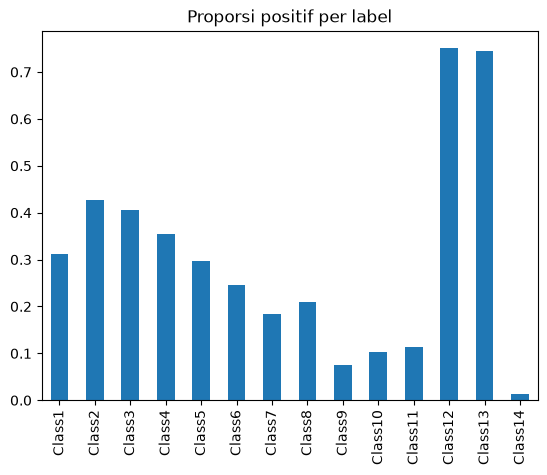

rata-rata jumlah label per baris: 4.24


In [4]:
train[LABELS].mean().plot.bar()
plt.title("Proporsi positif per label")
plt.show()

labels_per_row = train[LABELS].sum(axis=1)
print("rata-rata jumlah label per baris:", round(labels_per_row.mean(), 2))

## Split train / validasi
`y` di sini berupa tabel: satu kolom per label.

In [5]:
X = train[FEATURES]
y = train[LABELS]
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=SEED)

## Model
- `MultiOutputClassifier(...)` = satu model terpisah untuk tiap label.
- `ClassifierChain(...)` = tebakan label sebelumnya ikut dipakai sebagai feature.
- RandomForest / ExtraTrees / KNN bisa langsung multilabel tanpa pembungkus.

Pilih SATU model: hapus `#` di baris yang ingin dipakai, beri `#` pada baris lain.

In [6]:
model = MultiOutputClassifier(LogisticRegression(C=1.0, max_iter=2000))
# model = MultiOutputClassifier(LGBMClassifier(n_estimators=300, verbose=-1))
# model = ClassifierChain(LogisticRegression(C=1.0, max_iter=2000), random_state=SEED)
# model = RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1)
# model = ExtraTreesClassifier(n_estimators=500, random_state=SEED, n_jobs=-1)
# model = KNeighborsClassifier(n_neighbors=15)
# model = MultiOutputClassifier(XGBClassifier(n_estimators=300, random_state=SEED))
# model = ClassifierChain(LGBMClassifier(n_estimators=300, verbose=-1), random_state=SEED)
# model = MLPClassifier(hidden_layer_sizes=(128,), max_iter=1000, random_state=SEED)
# model = MultiOutputClassifier(SVC(C=1.0, random_state=SEED))

pipe = make_pipeline(StandardScaler(), model)
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('multioutputclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.",list,"[array([0, 1]), array([0, 1]), array([0, 1]), array([0, 1]), ...]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](103,)","['Att1','Att2','Att3',...,'Att101','Att102','Att103']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,103
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## Evaluasi di validasi
- F1 micro: semua sel label dihitung bersama (label besar lebih berpengaruh).
- F1 macro: rata-rata F1 per label (semua label sama penting).
- Hamming loss: proporsi sel label yang salah (makin kecil makin bagus).

In [7]:
val_predictions = pipe.predict(X_val)
print("F1 micro    :", round(f1_score(y_val, val_predictions, average="micro"), 4))
print("F1 macro    :", round(f1_score(y_val, val_predictions, average="macro"), 4))
print("Hamming loss:", round(hamming_loss(y_val, val_predictions), 4))

f1_per_label = f1_score(y_val, val_predictions, average=None, zero_division=0)
pd.Series(f1_per_label, index=LABELS).round(3)

F1 micro    : 0.6212
F1 macro    : 0.3827
Hamming loss: 0.2107


Class1     0.609
Class2     0.518
Class3     0.645
Class4     0.617
Class5     0.468
Class6     0.309
Class7     0.178
Class8     0.157
Class9     0.067
Class10    0.000
Class11    0.120
Class12    0.845
Class13    0.826
Class14    0.000
dtype: float64

## Latih ulang di semua data + submission
`predictions[:, 0]` = kolom tebakan label pertama, `[:, 1]` = label kedua, dst.

In [8]:
pipe.fit(X, y)
predictions = pipe.predict(test[FEATURES])

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["Class1"] = predictions[:, 0]
submission["Class2"] = predictions[:, 1]
submission["Class3"] = predictions[:, 2]
submission["Class4"] = predictions[:, 3]
submission["Class5"] = predictions[:, 4]
submission["Class6"] = predictions[:, 5]
submission["Class7"] = predictions[:, 6]
submission["Class8"] = predictions[:, 7]
submission["Class9"] = predictions[:, 8]
submission["Class10"] = predictions[:, 9]
submission["Class11"] = predictions[:, 10]
submission["Class12"] = predictions[:, 11]
submission["Class13"] = predictions[:, 12]
submission["Class14"] = predictions[:, 13]
submission.to_csv("submission.csv", index=False)
submission.head()

,id,Class1,Class2,Class3,Class4,Class5,Class6,Class7,Class8,Class9,Class10,Class11,Class12,Class13,Class14
0,411,0,0,0,0,1,0,1,1,0,0,0,1,1,0
1,200,0,0,0,0,0,0,0,0,0,0,0,1,1,0
2,1673,1,1,1,0,0,0,0,0,0,0,0,1,1,0
3,2336,0,0,0,0,0,0,0,0,0,0,0,1,1,0
4,1038,0,0,1,1,0,0,0,0,0,0,0,1,1,0
